In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

import warnings
warnings.filterwarnings('ignore')

print('All libraries imported successfully!')

All libraries imported successfully!


In [2]:
# Load the dataset
from pathlib import Path

# Works whether Jupyter is started from the repo root or from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
df = pd.read_csv(ROOT / 'Mall_Customers.csv')

# Rename columns for easier use
df.columns = ['CustomerID', 'Gender', 'Age', 'Annual_Income', 'Spending_Score']

print('Shape:', df.shape)
df.head()

Shape: (200, 5)


,CustomerID,Gender,Age,Annual_Income,Spending_Score
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
# Basic statistics
df.describe()

,CustomerID,Age,Annual_Income,Spending_Score
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [4]:
# Check for missing values
print('Missing values:')
print(df.isnull().sum())


Missing values:
CustomerID        0
Gender            0
Age               0
Annual_Income     0
Spending_Score    0
dtype: int64


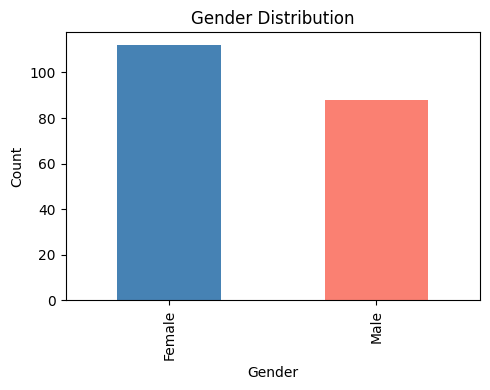

In [5]:
# Gender distribution
plt.figure(figsize=(5,4))
df['Gender'].value_counts().plot(kind='bar', color=['steelblue', 'salmon'])
plt.title('Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

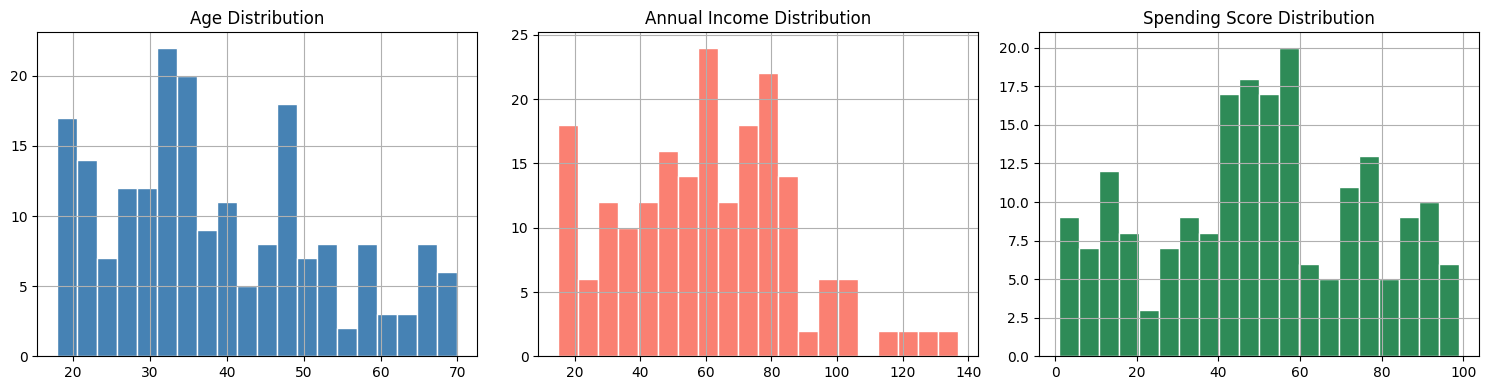

In [6]:
# Histograms for numeric columns
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

df['Age'].hist(ax=axes[0], bins=20, color='steelblue', edgecolor='white')
axes[0].set_title('Age Distribution')

df['Annual_Income'].hist(ax=axes[1], bins=20, color='salmon', edgecolor='white')
axes[1].set_title('Annual Income Distribution')

df['Spending_Score'].hist(ax=axes[2], bins=20, color='seagreen', edgecolor='white')
axes[2].set_title('Spending Score Distribution')

plt.tight_layout()
plt.show()

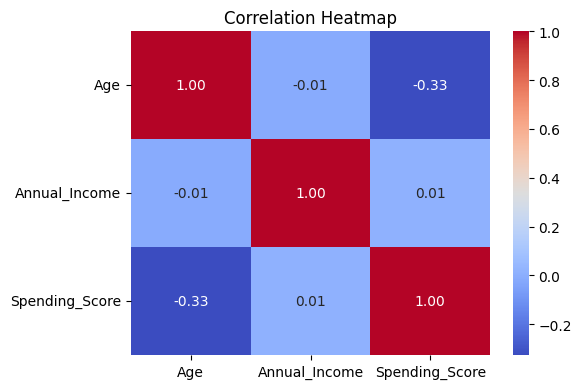

In [7]:
# Correlation heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(df[['Age', 'Annual_Income', 'Spending_Score']].corr(), 
            annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

In [8]:
# We use Income and Spending Score (the 2 most important features)
X = df[['Annual_Income', 'Spending_Score']].values

# Normalize
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print('Data normalized. Shape:', X_scaled.shape)

Data normalized. Shape: (200, 2)


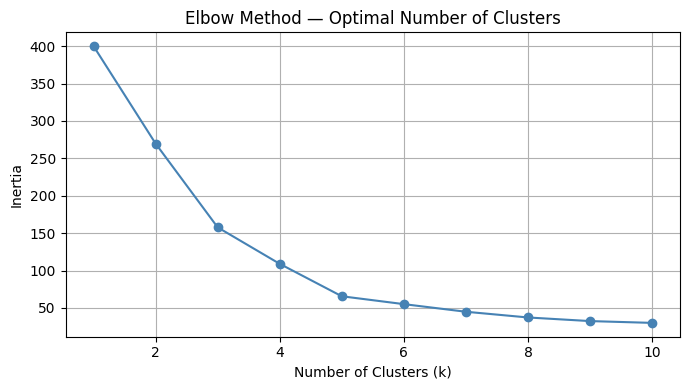

Look at the plot — choose k where the curve bends (usually k=5)


In [9]:
# Elbow Method — find the best number of clusters
inertia = []
k_range = range(1, 11)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertia.append(km.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(k_range, inertia, marker='o', color='steelblue')
plt.title('Elbow Method — Optimal Number of Clusters')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.grid(True)
plt.tight_layout()
plt.show()

print('Look at the plot — choose k where the curve bends (usually k=5)')

In [10]:
# Apply K-Means with k=5
km = KMeans(n_clusters=5, random_state=42, n_init=10)
df['Cluster_KMeans'] = km.fit_predict(X_scaled)

# Silhouette Score
score = silhouette_score(X_scaled, df['Cluster_KMeans'])
print(f'Silhouette Score (K-Means): {score:.3f}  →  closer to 1 is better')

Silhouette Score (K-Means): 0.555  →  closer to 1 is better


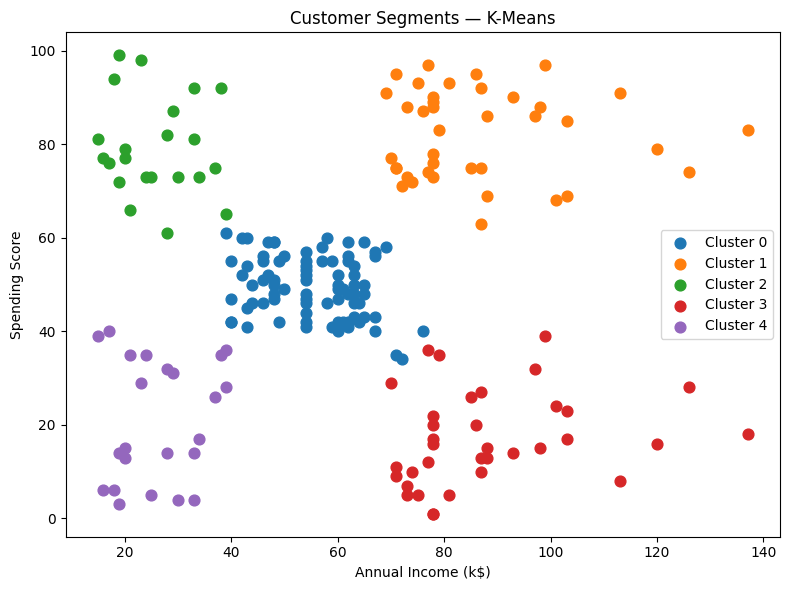

In [11]:
# Visualize K-Means clusters
colors = ['red', 'blue', 'green', 'orange', 'purple']

plt.figure(figsize=(8, 6))
for i in range(5):
    cluster_data = df[df['Cluster_KMeans'] == i]
    plt.scatter(cluster_data['Annual_Income'], cluster_data['Spending_Score'],
                label=f'Cluster {i}', s=60)

plt.title('Customer Segments — K-Means')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score')
plt.legend()
plt.tight_layout()
plt.show()

In [12]:
# Apply DBSCAN
db = DBSCAN(eps=0.5, min_samples=5)
df['Cluster_DBSCAN'] = db.fit_predict(X_scaled)

n_clusters = len(set(df['Cluster_DBSCAN'])) - (1 if -1 in df['Cluster_DBSCAN'].values else 0)
n_noise = list(df['Cluster_DBSCAN']).count(-1)

print(f'DBSCAN found {n_clusters} clusters')
print(f'Noise points (outliers): {n_noise}')

DBSCAN found 2 clusters
Noise points (outliers): 8


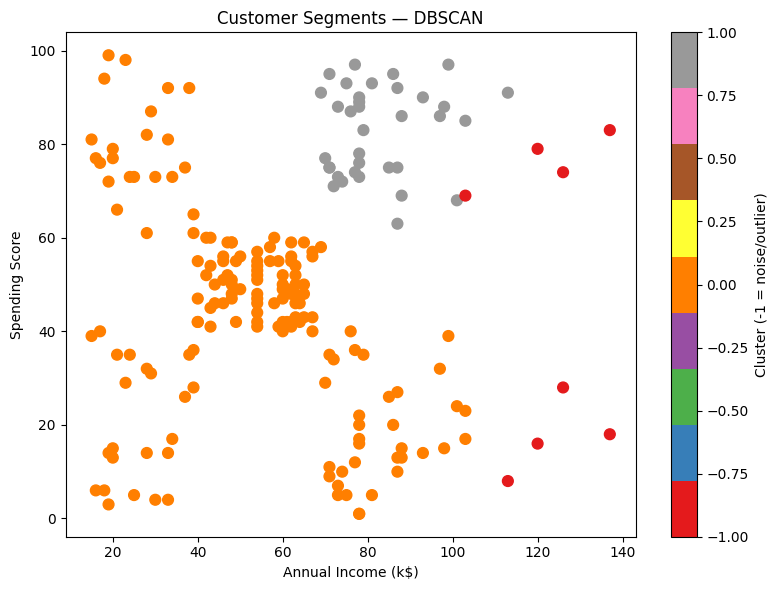

In [13]:
# Visualize DBSCAN clusters
plt.figure(figsize=(8, 6))
scatter = plt.scatter(df['Annual_Income'], df['Spending_Score'],
                      c=df['Cluster_DBSCAN'], cmap='Set1', s=60)
plt.title('Customer Segments — DBSCAN')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score')
plt.colorbar(scatter, label='Cluster (-1 = noise/outlier)')
plt.tight_layout()
plt.show()

In [14]:
# Average Income and Spending Score per cluster
cluster_summary = df.groupby('Cluster_KMeans')[['Age', 'Annual_Income', 'Spending_Score']].mean().round(1)
cluster_summary['Count'] = df.groupby('Cluster_KMeans')['CustomerID'].count()

print('Cluster Summary:')
print(cluster_summary)

Cluster Summary:
                 Age  Annual_Income  Spending_Score  Count
Cluster_KMeans                                            
0               42.7           55.3            49.5     81
1               32.7           86.5            82.1     39
2               25.3           25.7            79.4     22
3               41.1           88.2            17.1     35
4               45.2           26.3            20.9     23


In [15]:
# These labels match the cluster averages printed in the summary above.
# Cluster IDs are arbitrary and may change if the model is retrained.
cluster_names = {
    0: 'Moderate-Income, Moderate-Spending Customers',
    1: 'High-Income, High-Spending Customers',
    2: 'Lower-Income, High-Spending Customers',
    3: 'High-Income, Low-Spending Customers',
    4: 'Lower-Income, Low-Spending Customers'
}

df['Segment'] = df['Cluster_KMeans'].map(cluster_names)
print(df['Segment'].value_counts())


Segment
Moderate-Income, Moderate-Spending Customers    81
High-Income, High-Spending Customers            39
High-Income, Low-Spending Customers             35
Lower-Income, Low-Spending Customers            23
Lower-Income, High-Spending Customers           22
Name: count, dtype: int64


In [16]:
recommendations = {
    'High-Income, High-Spending Customers': 'Test VIP loyalty benefits and personalized premium offers.',
    'Lower-Income, Low-Spending Customers': 'Test value-focused offers and discounts.',
    'Moderate-Income, Moderate-Spending Customers': 'Test seasonal campaigns, bundles, and loyalty offers.',
    'High-Income, Low-Spending Customers': 'Test product discovery and targeted recommendations.',
    'Lower-Income, High-Spending Customers': 'Test trend-focused products and accessible promotions.'
}

print('=== ILLUSTRATIVE MARKETING HYPOTHESES ===')
for segment, advice in recommendations.items():
    print(f'\n{segment}\n  {advice}')


=== ILLUSTRATIVE MARKETING HYPOTHESES ===

High-Income, High-Spending Customers
  Test VIP loyalty benefits and personalized premium offers.

Lower-Income, Low-Spending Customers
  Test value-focused offers and discounts.

Moderate-Income, Moderate-Spending Customers
  Test seasonal campaigns, bundles, and loyalty offers.

High-Income, Low-Spending Customers
  Test product discovery and targeted recommendations.

Lower-Income, High-Spending Customers
  Test trend-focused products and accessible promotions.


In [17]:
# Final comparison: K-Means vs DBSCAN
print('=== MODEL COMPARISON ===')
print(f'K-Means  →  5 clusters, Silhouette Score: {score:.3f}')
print(f'DBSCAN   →  {n_clusters} clusters, {n_noise} outliers detected')
print('\nConclusion: K-Means gives cleaner and more interpretable segments for marketing purposes.')

=== MODEL COMPARISON ===
K-Means  →  5 clusters, Silhouette Score: 0.555
DBSCAN   →  2 clusters, 8 outliers detected

Conclusion: K-Means gives cleaner and more interpretable segments for marketing purposes.


In [18]:
import joblib

joblib.dump(km, ROOT / "kmeans_model.pkl")
joblib.dump(scaler, ROOT / "scaler.pkl")

['/tmp/nbrun/scaler.pkl']